# Exploratory Data Analysis for Research Question 1

## Research Question 1
How have family-sponsored Visa Bulletin cutoff dates changed from October 2016 to September 2026?

This notebook explores the cleaned Visa Bulletin dataset to identify overall cutoff date trends, monthly movement patterns, Current periods, and differences across visa categories and chargeability areas.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Find the main project folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

q1_path = PROCESSED_DIR / "visa_bulletins_analysisQ1.csv"

q1_df = pd.read_csv(
    q1_path,
    parse_dates=["bulletin_date", "cutoff_date"]
)

print("Dataset shape:", q1_df.shape)

q1_df.head()

Dataset shape: (6000, 7)


,bulletin_date,visa_category,chargeability_area,table_type,cutoff_date,cutoff_status,movement_days
0,2016-10-31,F1,All Chargeability Areas Except Those Listed,Dates for Filing,2011-01-01,Date,NaN
1,2016-11-30,F1,All Chargeability Areas Except Those Listed,Dates for Filing,2011-01-01,Date,0.0
2,2016-12-31,F1,All Chargeability Areas Except Those Listed,Dates for Filing,2011-01-01,Date,0.0
3,2017-01-31,F1,All Chargeability Areas Except Those Listed,Dates for Filing,2011-01-01,Date,0.0
4,2017-02-28,F1,All Chargeability Areas Except Those Listed,Dates for Filing,2011-01-01,Date,0.0


In [6]:
# Basic overview of the Q1 dataset.

print("Date range:")
print("Start:", q1_df["bulletin_date"].min())
print("End:", q1_df["bulletin_date"].max())

print("\nCutoff date:")
print("Min cutoff date:", q1_df["cutoff_date"].min())
print("Max cutoff date", q1_df["cutoff_date"].max())

print("\nVisa categories:")
print(q1_df["visa_category"].unique())

print("\nChargeability areas:")
print(q1_df["chargeability_area"].unique())

print("\nTable types:")
print(q1_df["table_type"].unique())

Date range:
Start: 2016-10-31 00:00:00
End: 2026-09-30 00:00:00

Cutoff date:
Min cutoff date: 1993-04-15 00:00:00
Max cutoff date 2026-09-30 00:00:00

Visa categories:
<StringArray>
['F1', 'F2A', 'F2B', 'F3', 'F4']
Length: 5, dtype: str

Chargeability areas:
<StringArray>
['All Chargeability Areas Except Those Listed',
                                       'China',
                                       'India',
                                      'Mexico',
                                 'Philippines']
Length: 5, dtype: str

Table types:
<StringArray>
['Dates for Filing', 'Final Action']
Length: 2, dtype: str


In [7]:
# Check whether every category-area-table combination
# contains all 120 monthly bulletins.

group_counts = (
    q1_df.groupby(
        [
            "visa_category",
            "chargeability_area",
            "table_type"
        ]
    )
    .size()
    .reset_index(name="record_count")
)

group_counts

,visa_category,chargeability_area,table_type,record_count
0,F1,All Chargeability Areas Except Those Listed,Dates for Filing,120
1,F1,All Chargeability Areas Except Those Listed,Final Action,120
2,F1,China,Dates for Filing,120
3,F1,China,Final Action,120
4,F1,India,Dates for Filing,120
5,F1,India,Final Action,120
6,F1,Mexico,Dates for Filing,120
7,F1,Mexico,Final Action,120
8,F1,Philippines,Dates for Filing,120
9,F1,Philippines,Final Action,120


In [8]:
print("Minimum records per group:", group_counts["record_count"].min())
print("Maximum records per group:", group_counts["record_count"].max())
print("Number of groups:", len(group_counts))

Minimum records per group: 120
Maximum records per group: 120
Number of groups: 50


### Dataset Completeness Check

The expected number of records and groups was confirmed. All 50 category-area-table combinations contain 120 monthly observations, indicating that the dataset is complete and correctly grouped for the study period.

In [9]:
# Check how many records contain an actual cutoff date
# and how many are marked as Current.

status_counts = q1_df["cutoff_status"].value_counts()

print(status_counts)

cutoff_status
Date       5662
Current     338
Name: count, dtype: int64


In [46]:
# Compare cutoff status across visa categories. #NICE

status_by_category = pd.crosstab(
    index=q1_df["visa_category"],
    columns=[
        q1_df["table_type"],
        q1_df["cutoff_status"]
    ]
)


status_by_category

table_type    Dates for Filing      Final Action     
cutoff_status          Current Date      Current Date
visa_category                                        
F1                           0  600            0  600
F2A                        115  485          223  377
F2B                          0  600            0  600
F3                           0  600            0  600
F4                           0  600            0  600

In [47]:
# Compare monthly movement separately for each table type. #fixed

for table_type in ["Final Action", "Dates for Filing"]:

    table_df = q1_df[
        q1_df["table_type"] == table_type
    ]

    print(f"\n{table_type}")
    print(table_df["movement_days"].describe())

    print("\nMovement direction counts:")
    print("Advance:", (table_df["movement_days"] > 0).sum())
    print("No Movement:", (table_df["movement_days"] == 0).sum())
    print("Retrogress:", (table_df["movement_days"] < 0).sum())


Final Action
count    2975.000000
mean       30.002689
std       113.221130
min     -1611.000000
25%         0.000000
50%        14.000000
75%        31.000000
max      1288.000000
Name: movement_days, dtype: float64

Movement direction counts:
Advance: 1737
No Movement: 1208
Retrogress: 30

Dates for Filing
count    2975.000000
mean       28.283697
std        68.775676
min         0.000000
25%         0.000000
50%         0.000000
75%        31.000000
max       853.000000
Name: movement_days, dtype: float64

Movement direction counts:
Advance: 1115
No Movement: 1860
Retrogress: 0


### Monthly Movement Overview[need review.]
(The 50 missing movement values are expected because each of the 50 category-area-table groups has no previous observation for its first month.)

Monthly cutoff movement is frequently unchanged. 
The median (50%) movement is 0 days, and 3,068 observations show no movement, compared with 2,852 advances and only 30 retrogressions.

The movement range is wide, from -1,611 to +1,288 days, suggesting that a small number of months experienced unusually large changes.

In [48]:
# Compare movement direction across visa categories
# separately for each table type.

for table_type in ["Final Action", "Dates for Filing"]:

    table_df = q1_df[
        q1_df["table_type"] == table_type
    ]

    movement_by_category = pd.crosstab(
        index=table_df["visa_category"],
        columns=pd.cut(
            table_df["movement_days"],
            bins=[float("-inf"), -0.0001, 0, float("inf")],
            labels=["Retrogress", "No Movement", "Advance"]
        )
    )

    print(f"\n{table_type}")
    display(movement_by_category)


Final Action


movement_days,Retrogress,No Movement,Advance
visa_category,,,
F1,8,284,303
F2A,11,126,458
F2B,1,271,323
F3,4,248,343
F4,6,279,310



Dates for Filing


movement_days,No Movement,Advance
visa_category,,
F1,407,188
F2A,245,350
F2B,401,194
F3,402,193
F4,405,190


In [ ]:
# OVERALL: Combines Final Action and Dates for Filing.
# Shows movement percentages by visa category and chargeability area.

# Create movement direction categories.
movement_direction = pd.cut(
    q1_df["movement_days"],
    bins=[float("-inf"), -0.0001, 0, float("inf")],
    labels=["Retrogress", "No Movement", "Advance"]
)

# Count movement directions by visa category and chargeability area.
movement_counts = pd.crosstab(
    index=q1_df["visa_category"],
    columns=[
        q1_df["chargeability_area"],
        movement_direction
    ]
)

# Convert counts to percentages within each chargeability area.
movement_percent_by_area = movement_counts.astype(float)

for area in q1_df["chargeability_area"].unique():

    area_total = movement_counts[area].sum(axis=1)

    movement_percent_by_area[area] = (
        movement_counts[area]
        .div(area_total, axis=0)
        * 100
    )

movement_percent_by_area.round(1)



chargeability_area All Chargeability Areas Except Those Listed              \
movement_days                                       Retrogress No Movement   
visa_category                                                                
F1                                                         0.8        57.1   
F2A                                                        0.8        31.1   
F2B                                                        0.0        56.7   
F3                                                         0.4        51.3   
F4                                                         0.8        56.7   

chargeability_area              China                          India  \
movement_days      Advance Retrogress No Movement Advance Retrogress   
visa_category                                                          
F1                    42.0        0.8        57.1    42.0        0.8   
F2A                   68.1        0.8        31.1    68.1        0.8   
F2B                   43.3        0.0        56.7    43.3        0.0   
F3                    48.3        0.4        51.3    48.3        0.4   
F4                    42.4        0.8        56.7    42.4        0.4   

chargeability_area                         Mexico                      \
movement_days      No Movement Advance Retrogress No Movement Advance   
visa_category                                                           
F1                        57.1    42.0        0.4        54.2    45.4   
F2A                       31.1    68.1        1.3        31.5    67.2   
F2B                       56.7    43.3        0.0        48.7    51.3   
F3                        51.3    48.3        0.4        63.4    36.1   
F4                        59.2    40.3        0.4        61.8    37.8   

chargeability_area Philippines                      
movement_days       Retrogress No Movement Advance  
visa_category                                       
F1                         0.4        64.7    34.9  
F2A                        0.8        31.1    68.1  
F2B                        0.4        63.4    36.1  
F3                         0.0        55.9    44.1  
F4                         0.0        52.9    47.1

In [50]:
# FINAL ACTION: Movement percentages by visa category and chargeability area.

final_action_df = q1_df[
    q1_df["table_type"] == "Final Action"
]

final_action_direction = pd.cut(
    final_action_df["movement_days"],
    bins=[float("-inf"), -0.0001, 0, float("inf")],
    labels=["Retrogress", "No Movement", "Advance"]
)

final_action_counts = pd.crosstab(
    index=final_action_df["visa_category"],
    columns=[
        final_action_df["chargeability_area"],
        final_action_direction
    ]
)

final_action_percent = final_action_counts.astype(float)

for area in final_action_df["chargeability_area"].unique():

    area_total = final_action_counts[area].sum(axis=1)

    final_action_percent[area] = (
        final_action_counts[area]
        .div(area_total, axis=0)
        * 100
    )

final_action_percent.round(1)

chargeability_area All Chargeability Areas Except Those Listed              \
movement_days                                       Retrogress No Movement   
visa_category                                                                
F1                                                         1.7        46.2   
F2A                                                        1.7        21.0   
F2B                                                        0.0        45.4   
F3                                                         0.8        38.7   
F4                                                         1.7        47.1   

chargeability_area              China                          India  \
movement_days      Advance Retrogress No Movement Advance Retrogress   
visa_category                                                          
F1                    52.1        1.7        46.2    52.1        1.7   
F2A                   77.3        1.7        21.0    77.3        1.7   
F2B                   54.6        0.0        45.4    54.6        0.0   
F3                    60.5        0.8        38.7    60.5        0.8   
F4                    51.3        1.7        47.1    51.3        0.8   

chargeability_area                         Mexico                      \
movement_days      No Movement Advance Retrogress No Movement Advance   
visa_category                                                           
F1                        46.2    52.1        0.8        46.2    52.9   
F2A                       21.0    77.3        2.5        21.8    75.6   
F2B                       45.4    54.6        0.0        40.3    59.7   
F3                        38.7    60.5        0.8        46.2    52.9   
F4                        46.2    52.9        0.8        54.6    44.5   

chargeability_area Philippines                      
movement_days       Retrogress No Movement Advance  
visa_category                                       
F1                         0.8        53.8    45.4  
F2A                        1.7        21.0    77.3  
F2B                        0.8        51.3    47.9  
F3                         0.0        46.2    53.8  
F4                         0.0        39.5    60.5

In [51]:
# DATES FOR FILING: Movement percentages by visa category and chargeability area.

filing_df = q1_df[
    q1_df["table_type"] == "Dates for Filing"
]

filing_direction = pd.cut(
    filing_df["movement_days"],
    bins=[float("-inf"), -0.0001, 0, float("inf")],
    labels=["Retrogress", "No Movement", "Advance"]
)

filing_counts = pd.crosstab(
    index=filing_df["visa_category"],
    columns=[
        filing_df["chargeability_area"],
        filing_direction
    ]
)

filing_percent = filing_counts.astype(float)

for area in filing_df["chargeability_area"].unique():

    area_total = filing_counts[area].sum(axis=1)

    filing_percent[area] = (
        filing_counts[area]
        .div(area_total, axis=0)
        * 100
    )

filing_percent.round(1)

chargeability_area All Chargeability Areas Except Those Listed          \
movement_days                                      No Movement Advance   
visa_category                                                            
F1                                                        68.1    31.9   
F2A                                                       41.2    58.8   
F2B                                                       68.1    31.9   
F3                                                        63.9    36.1   
F4                                                        66.4    33.6   

chargeability_area       China               India              Mexico  \
movement_days      No Movement Advance No Movement Advance No Movement   
visa_category                                                            
F1                        68.1    31.9        68.1    31.9        62.2   
F2A                       41.2    58.8        41.2    58.8        41.2   
F2B                       68.1    31.9        68.1    31.9        57.1   
F3                        63.9    36.1        63.9    36.1        80.7   
F4                        66.4    33.6        72.3    27.7        68.9   

chargeability_area         Philippines          
movement_days      Advance No Movement Advance  
visa_category                                   
F1                    37.8        75.6    24.4  
F2A                   58.8        41.2    58.8  
F2B                   42.9        75.6    24.4  
F3                    19.3        65.5    34.5  
F4                    31.1        66.4    33.6

In [60]:
# OVERALL: Find the highest movement percentage for each visa category
# using both Final Action and Dates for Filing together.
# If multiple chargeability areas share the highest value,
# combine them into one cell.

highest_overall = []

for category in movement_percent_by_area.index:

    category_values = movement_percent_by_area.loc[category]

    highest_value = category_values.max()

    highest_columns = category_values[
        category_values == highest_value
    ].index

    areas = list(dict.fromkeys(
        area
        for area, movement in highest_columns
    ))

    movements = list(dict.fromkeys(
        movement
        for area, movement in highest_columns
    ))

    highest_overall.append({
        "visa_category": category,
        "chargeability_area": ", ".join(areas),
        "movement_direction": ", ".join(movements),
        "percentage": round(highest_value, 1)
    })

highest_overall = pd.DataFrame(highest_overall)

pd.set_option("display.max_colwidth", None)

highest_overall

,visa_category,chargeability_area,movement_direction,percentage
0,F1,Philippines,No Movement,64.7
1,F2A,"All Chargeability Areas Except Those Listed, China, India, Philippines",Advance,68.1
2,F2B,Philippines,No Movement,63.4
3,F3,Mexico,No Movement,63.4
4,F4,Mexico,No Movement,61.8


In [59]:
# Find the highest movement percentage for each visa category
# across both Final Action and Dates for Filing.
# If both table types share the highest percentage, list both.

highest_across_tables = []

for category in q1_df["visa_category"].unique():

    candidates = []

    # Final Action values
    for (area, movement), percentage in final_action_percent.loc[category].items():
        candidates.append({
            "table_type": "Final Action",
            "chargeability_area": area,
            "movement_direction": movement,
            "percentage": percentage
        })

    # Dates for Filing values
    for (area, movement), percentage in filing_percent.loc[category].items():
        candidates.append({
            "table_type": "Dates for Filing",
            "chargeability_area": area,
            "movement_direction": movement,
            "percentage": percentage
        })

    # Highest percentage across both table types
    highest_value = max(
        item["percentage"]
        for item in candidates
    )

    # Keep every result tied for the highest value
    highest_matches = [
        item
        for item in candidates
        if item["percentage"] == highest_value
    ]

    table_types = list(dict.fromkeys(
        item["table_type"]
        for item in highest_matches
    ))

    movements = list(dict.fromkeys(
        item["movement_direction"]
        for item in highest_matches
    ))

    # Keep the chargeability areas connected to their table type
    area_details = []

    for table_type in table_types:

        areas = list(dict.fromkeys(
            item["chargeability_area"]
            for item in highest_matches
            if item["table_type"] == table_type
        ))

        if len(table_types) == 1:
            area_details.extend(areas)
        else:
            area_details.append(
                f"{table_type}: {', '.join(areas)}"
            )

    highest_across_tables.append({
        "visa_category": category,
        "table_type": ", ".join(table_types),
        "chargeability_area": "; ".join(area_details),
        "movement_direction": ", ".join(movements),
        "percentage": round(highest_value, 1)
    })

highest_across_tables = pd.DataFrame(highest_across_tables)

pd.set_option("display.max_colwidth", None)

highest_across_tables

,visa_category,table_type,chargeability_area,movement_direction,percentage
0,F1,Dates for Filing,Philippines,No Movement,75.6
1,F2A,Final Action,All Chargeability Areas Except Those Listed; China; India; Philippines,Advance,77.3
2,F2B,Dates for Filing,Philippines,No Movement,75.6
3,F3,Dates for Filing,Mexico,No Movement,80.7
4,F4,Dates for Filing,India,No Movement,72.3


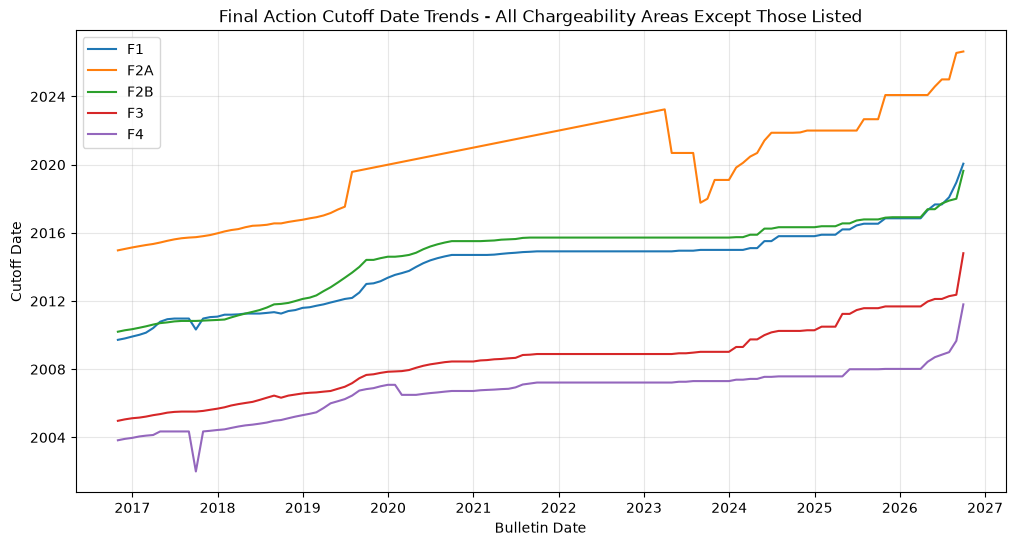

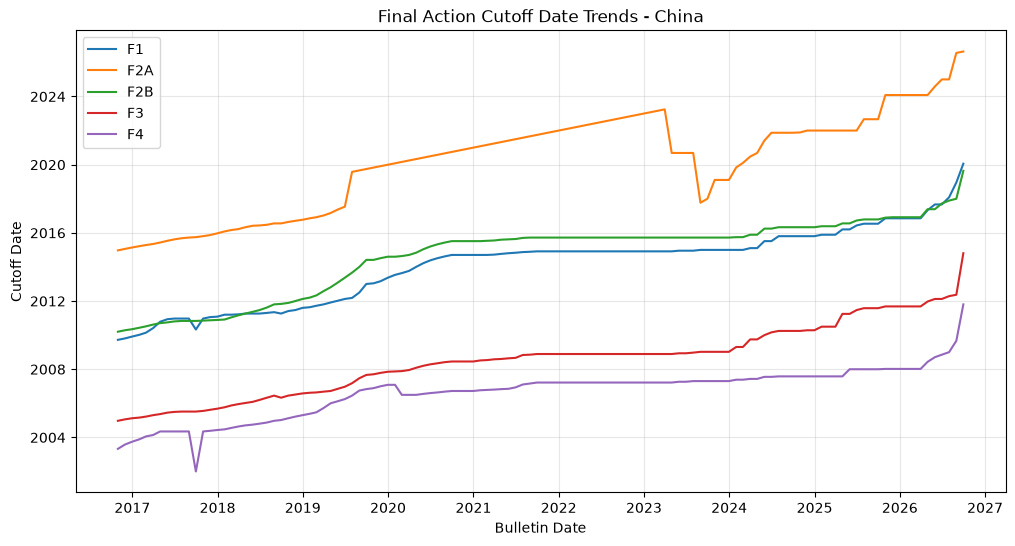

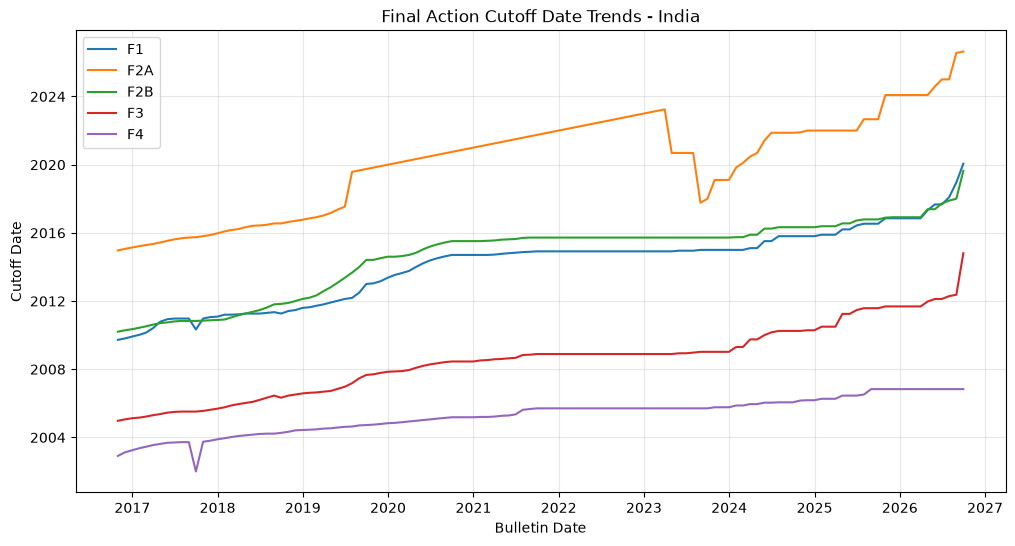

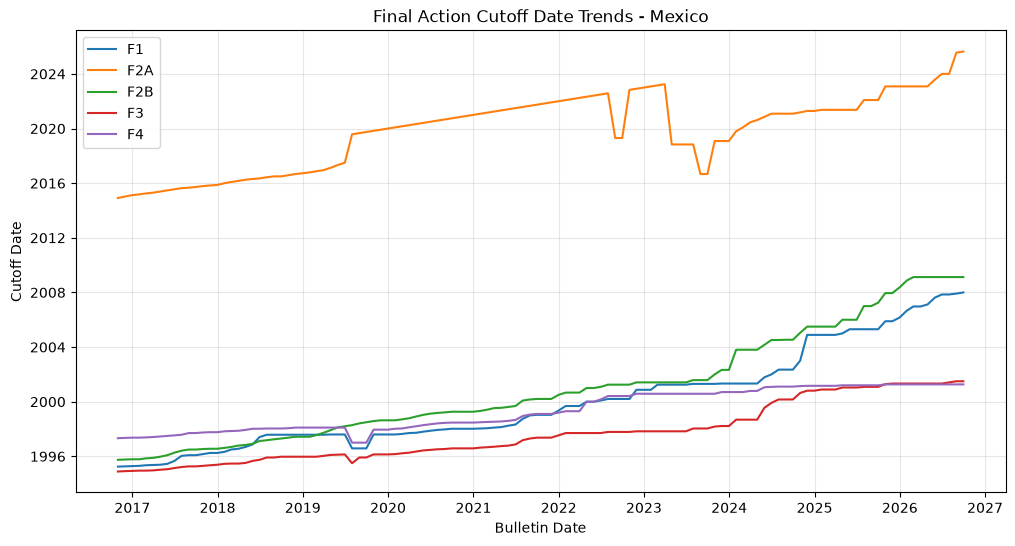

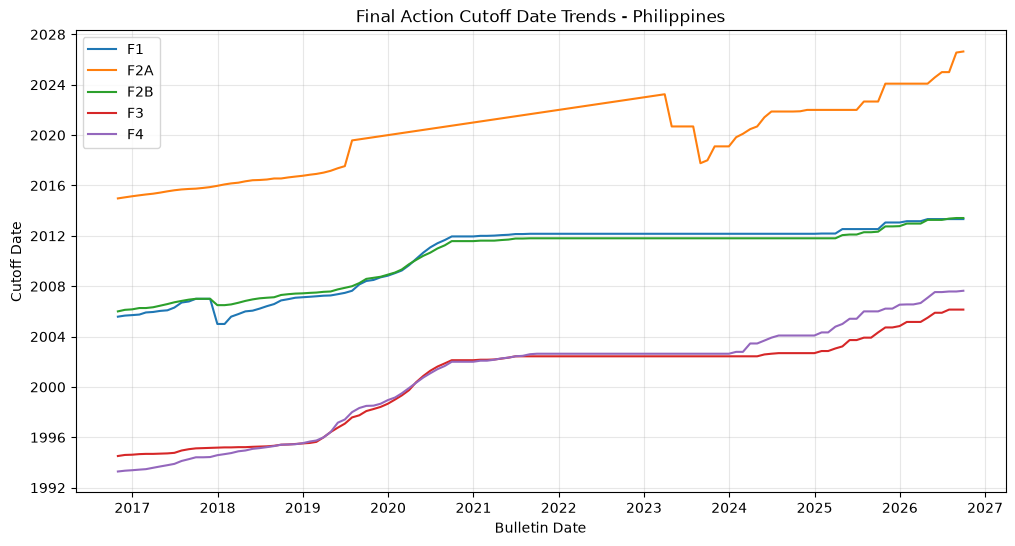

In [40]:
# Compare Final Action cutoff date trends across visa categories
# separately for each chargeability area.

areas = q1_df["chargeability_area"].unique()

for area in areas:

    trend_df = q1_df[
        (q1_df["table_type"] == "Final Action") &
        (q1_df["chargeability_area"] == area)
    ]

    plt.figure(figsize=(12, 6))

    for category in trend_df["visa_category"].unique():

        category_df = trend_df[
            trend_df["visa_category"] == category
        ]

        plt.plot(
            category_df["bulletin_date"],
            category_df["cutoff_date"],
            label=category
        )

    plt.xlabel("Bulletin Date")
    plt.ylabel("Cutoff Date")
    plt.title(
        f"Final Action Cutoff Date Trends - {area}"
    )

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

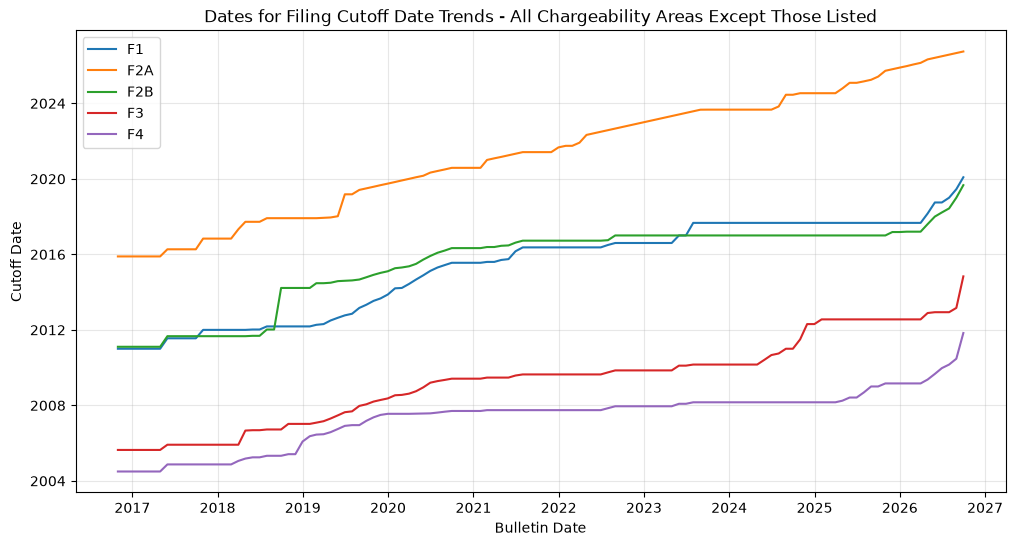

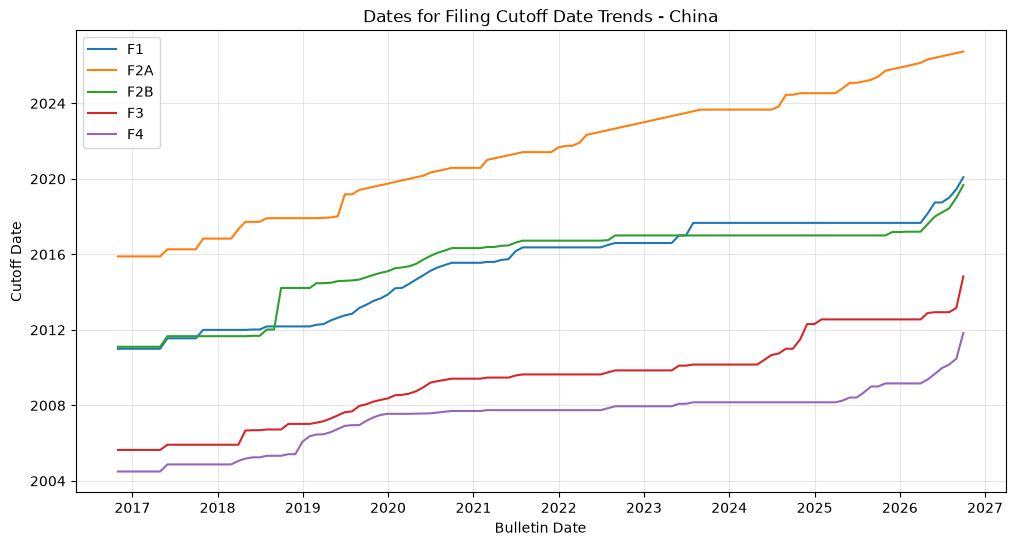

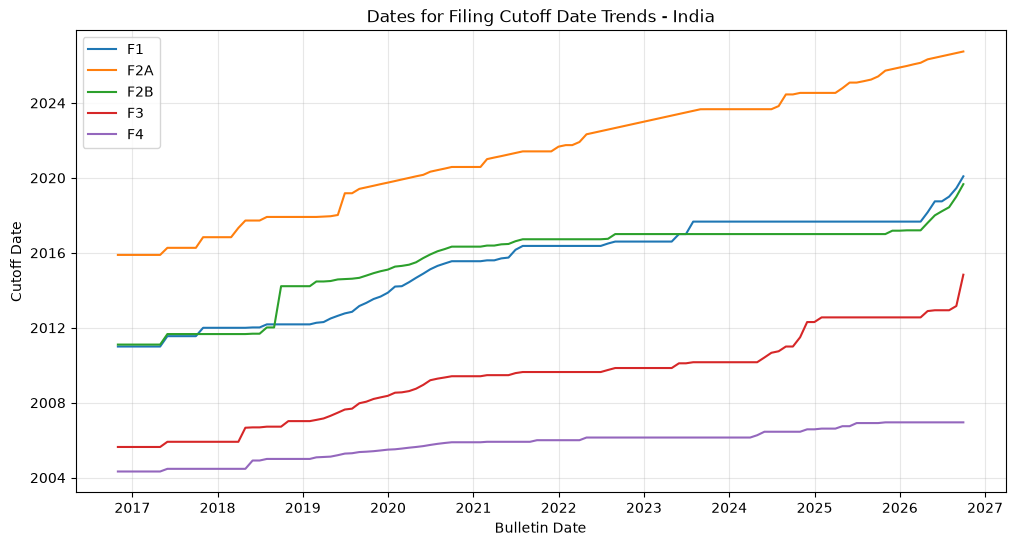

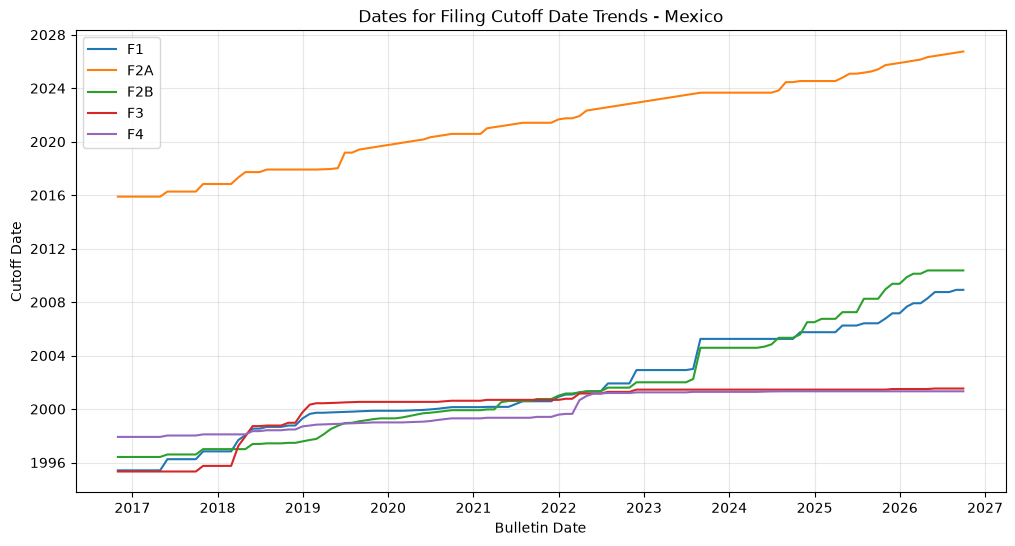

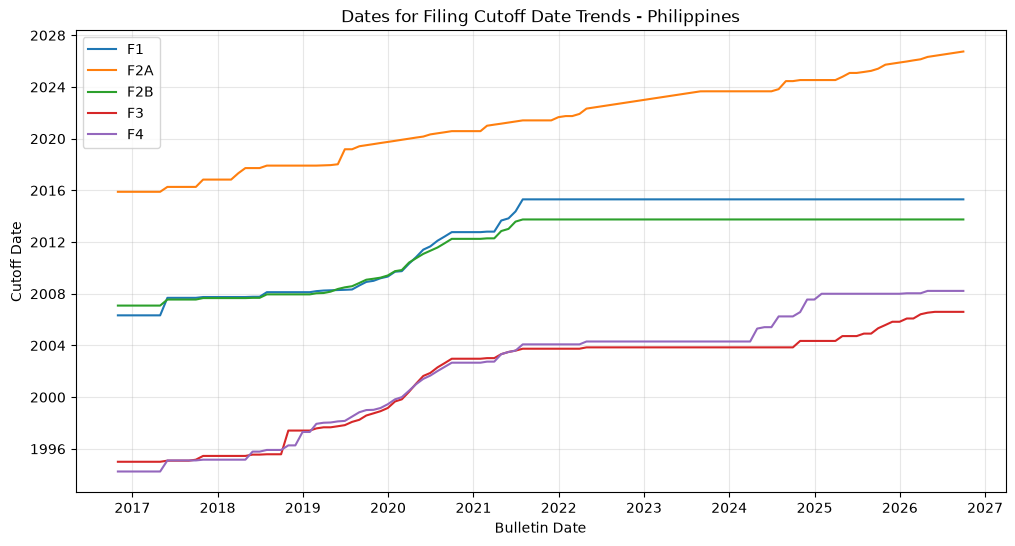

In [52]:
# Compare Dates for Filing cutoff date trends across visa categories
# separately for each chargeability area.

areas = q1_df["chargeability_area"].unique()

for area in areas:

    trend_df = q1_df[
        (q1_df["table_type"] == "Dates for Filing") &
        (q1_df["chargeability_area"] == area)
    ]

    plt.figure(figsize=(12, 6))

    for category in trend_df["visa_category"].unique():

        category_df = trend_df[
            trend_df["visa_category"] == category
        ]

        plt.plot(
            category_df["bulletin_date"],
            category_df["cutoff_date"],
            label=category
        )

    plt.xlabel("Bulletin Date")
    plt.ylabel("Cutoff Date")
    plt.title(
        f"Dates for Filing Cutoff Date Trends - {area}"
    )

    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [42]:
# Show the 10 largest monthly advances.

largest_advances = (
    q1_df[q1_df["movement_days"] > 0]
    .nlargest(10, "movement_days")
    [
        [
            "bulletin_date",
            "visa_category",
            "chargeability_area",
            "table_type",
            "cutoff_date",
            "cutoff_status",
            "movement_days"
        ]
    ]
)

largest_advances

,bulletin_date,visa_category,chargeability_area,table_type,cutoff_date,cutoff_status,movement_days
2112,2022-10-31,F2A,Mexico,Final Action,2022-10-31,Current,1288.0
3839,2026-09-30,F3,All Chargeability Areas Except Those Listed,Final Action,2014-10-22,Date,890.0
4079,2026-09-30,F3,China,Final Action,2014-10-22,Date,890.0
4319,2026-09-30,F3,India,Final Action,2014-10-22,Date,890.0
2124,2023-10-31,F2A,Mexico,Final Action,2019-02-01,Date,883.0
4932,2017-10-31,F4,All Chargeability Areas Except Those Listed,Final Action,2004-05-08,Date,858.0
5172,2017-10-31,F4,China,Final Action,2004-05-08,Date,858.0
3202,2023-08-31,F2B,Mexico,Dates for Filing,2004-08-01,Date,853.0
802,2023-08-31,F1,Mexico,Dates for Filing,2005-04-01,Date,821.0
2423,2018-09-30,F2B,All Chargeability Areas Except Those Listed,Dates for Filing,2014-03-22,Date,804.0


In [43]:
# Show the 10 largest monthly retrogressions.

largest_retrogressions = (
    q1_df[q1_df["movement_days"] < 0]
    .nsmallest(10, "movement_days")
    [
        [
            "bulletin_date",
            "visa_category",
            "chargeability_area",
            "table_type",
            "cutoff_date",
            "cutoff_status",
            "movement_days"
        ]
    ]
)

largest_retrogressions

,bulletin_date,visa_category,chargeability_area,table_type,cutoff_date,cutoff_status,movement_days
2118,2023-04-30,F2A,Mexico,Final Action,2018-11-01,Date,-1611.0
2110,2022-08-31,F2A,Mexico,Final Action,2019-04-22,Date,-1196.0
1402,2023-08-31,F2A,All Chargeability Areas Except Those Listed,Final Action,2017-10-08,Date,-1066.0
1642,2023-08-31,F2A,China,Final Action,2017-10-08,Date,-1066.0
1882,2023-08-31,F2A,India,Final Action,2017-10-08,Date,-1066.0
2362,2023-08-31,F2A,Philippines,Final Action,2017-10-08,Date,-1066.0
1398,2023-04-30,F2A,All Chargeability Areas Except Those Listed,Final Action,2020-09-08,Date,-934.0
1638,2023-04-30,F2A,China,Final Action,2020-09-08,Date,-934.0
1878,2023-04-30,F2A,India,Final Action,2020-09-08,Date,-934.0
2358,2023-04-30,F2A,Philippines,Final Action,2020-09-08,Date,-934.0
